# Notebook 3 — Transfer Learning | Protein Source Recognition

I wanted to answer one question: **does using a bigger pretrained image model actually improve protein recognition enough to justify the extra compute?** I’m testing MobileNetV2, ResNet50, and EfficientNetV2M with the same train/test data and the same simple classifier.

The pretrained models stay frozen. I only train a single Dense softmax layer on the image embeddings. This version processes a few images at a time because my original CPU run was heavier than it needed to be. The result should be the same kind of experiment, without keeping another copy of the whole image dataset in memory.

## 1. Load the data and set up the experiment

Notebook 2 already converted the photos to RGB, padded them to **224 × 224**, and stored raw **0–255** pixel values. I’m loading those saved arrays without copying them all into RAM. I use the same label mapping throughout the project.

In [1]:
from pathlib import Path
import gc, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

keras.utils.set_random_seed(42)

HERE = Path.cwd().resolve()
REPO = HERE.parent if HERE.name == "notebooks" else HERE
DATA_DIR = Path.home() / "MSDS565_data" / "P2_processed"
MODELS_DIR = REPO / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

required = [DATA_DIR / f for f in ("X_train.npy", "y_train.npy", "X_test.npy", "y_test.npy", "label_mapping.json")]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError("Missing Notebook 2 outputs: " + ", ".join(missing))

X_train = np.load(DATA_DIR / "X_train.npy", mmap_mode="r")
y_train = np.load(DATA_DIR / "y_train.npy")
X_test = np.load(DATA_DIR / "X_test.npy", mmap_mode="r")
y_test = np.load(DATA_DIR / "y_test.npy")
label_to_index = json.loads((DATA_DIR / "label_mapping.json").read_text())
class_names = [name for name, i in sorted(label_to_index.items(), key=lambda pair: pair[1])]
N_CLASSES = len(class_names)
INPUT_SHAPE = (224, 224, 3)
assert X_train.shape[1:] == X_test.shape[1:] == INPUT_SHAPE
assert X_train.dtype == X_test.dtype == np.uint8
assert set(np.unique(y_train)) == set(range(N_CLASSES))
(MODELS_DIR / "label_mapping.json").write_text(json.dumps(label_to_index, indent=2))

# A small batch uses less RAM, especially for EfficientNetV2M.
BATCH_SIZE = 4
PROBE_BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MAX_EPOCHS = 25

for device in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(device, True)
    except RuntimeError:
        pass

print("Training:", X_train.shape, "Testing:", X_test.shape)
print("Class labels:", class_names)
print("GPU detected:", tf.config.list_physical_devices("GPU"))
print("Embedding batch size:", BATCH_SIZE)

2026-11-17 20:35:52.492868: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Training: (1255, 224, 224, 3) Testing: (314, 224, 224, 3)
Class labels: ['beef', 'chicken', 'salmon', 'shrimp', 'tofu']
GPU detected: []
Embedding batch size: 4


## 2. Choose small, medium, and large pretrained backbones

| Size | Keras application | Approximate parameters | What its `preprocess_input` expects |
|---|---|---:|---|
| Small | MobileNetV2 | 3.5 million | Raw 0–255 inputs, converted to **−1 to +1** |
| Medium | ResNet50 | 25.6 million | Raw 0–255 inputs, converted to **BGR and ImageNet mean-centered** |
| Large | EfficientNetV2M | 54.4 million | **Raw 0–255**; rescaling is built into the backbone |

I picked a real difference in size so the performance comparison means something. The preprocessing changes between backbones because they were pretrained differently. **I do not normalize the saved arrays in place.**

In [2]:
MODEL_SPECS = {
    "mobilenetv2": {
        "constructor": keras.applications.MobileNetV2,
        "preprocess": keras.applications.mobilenet_v2.preprocess_input,
    },
    "resnet50": {
        "constructor": keras.applications.ResNet50,
        "preprocess": keras.applications.resnet.preprocess_input,
    },
    "efficientnetv2m": {
        "constructor": keras.applications.EfficientNetV2M,
        "preprocess": keras.applications.efficientnet_v2.preprocess_input,
    },
}

## 3. Balance, augment, then embed (training data only)

My class counts were already close, but I still balanced the **probe-training** portion by oversampling the smaller classes. Before that, I held out 15% of the training split for validation, so the model won’t see oversampled copies in validation.

For augmentation I use small rotations, zooms, and horizontal flips. Those should be reasonable for food photographs where the angle can change. I only augment training images—not validation or test images.

**Memory change:** instead of making a second giant array of augmented pictures, I transform one small batch immediately before embedding it. Then I discard that batch and move on. That keeps the required sequence (balance → augment → embed) but avoids holding thousands of transformed images in RAM.

In [3]:
fit_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.15, stratify=y_train, random_state=42
)
y_fit = y_train[fit_idx]
rng = np.random.default_rng(42)
max_count = max(np.sum(y_fit == c) for c in range(N_CLASSES))
fit_balanced_idx = np.concatenate([
    rng.choice(fit_idx[y_fit == c], size=max_count, replace=True)
    for c in range(N_CLASSES)
])
rng.shuffle(fit_balanced_idx)
y_fit_bal = y_train[fit_balanced_idx]
y_val = y_train[val_idx]

print("Before balance:", dict(zip(*np.unique(y_fit, return_counts=True))))
print("After balance:", dict(zip(*np.unique(y_fit_bal, return_counts=True))))
print("Validation:", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test (untouched):", dict(zip(*np.unique(y_test, return_counts=True))))

Before balance: {0: 227, 1: 217, 2: 212, 3: 210, 4: 200}
After balance: {0: 227, 1: 227, 2: 227, 3: 227, 4: 227}
Validation: {0: 40, 1: 38, 2: 38, 3: 37, 4: 36}
Test (untouched): {0: 67, 1: 64, 2: 63, 3: 61, 4: 59}


## 4. Extract frozen embeddings and train one linear probe at a time

I use exactly the same training settings for all three probes: **one Dense softmax layer**, Adam at **0.001**, batch size **32**, up to **25 epochs**, and early stopping on validation loss. Only the feature vector size changes.

Each model gets its own run cell below. I save its trained probe, predictions, confusion matrix, and timing immediately, so a crash on a later model doesn't wipe out earlier results.

**To retry a model from scratch**, set `FORCE_RERUN = True` temporarily. Otherwise a completed model is loaded from its saved result files instead of being trained again.

In [4]:
# Helpers — run this cell once before the three model cells.
FORCE_RERUN = False

def extract_embeddings(backbone, preprocess, source, indices, *, augment=False):
    """Work in tiny CPU/GPU batches. No full-size augmented image array."""
    augmenter = keras.Sequential([
        keras.layers.RandomFlip("horizontal", seed=42),
        keras.layers.RandomRotation(0.05, fill_mode="constant", seed=42),
        keras.layers.RandomZoom(0.08, fill_mode="constant", seed=42),
    ]) if augment else None
    features = []
    started = time.perf_counter()
    for start in range(0, len(indices), BATCH_SIZE):
        ids = indices[start:start + BATCH_SIZE]
        # Gather just these images and leave the memory-mapped original untouched.
        batch = tf.convert_to_tensor(np.asarray(source[ids]), dtype=tf.float32)
        if augmenter is not None:
            batch = augmenter(batch, training=True)
            batch = tf.clip_by_value(batch, 0.0, 255.0)
        batch = preprocess(batch)
        embeddings = backbone(batch, training=False)
        features.append(embeddings.numpy())
        del batch, embeddings
        if (start // BATCH_SIZE + 1) % 40 == 0 or start + BATCH_SIZE >= len(indices):
            print(f"  Embedded {min(start + BATCH_SIZE, len(indices))}/{len(indices)}", flush=True)
    out = np.concatenate(features, axis=0)
    del features, augmenter
    return out, time.perf_counter() - started


def make_probe(embedding_dim):
    return keras.Sequential([
        keras.Input(shape=(embedding_dim,)),
        keras.layers.Dense(N_CLASSES, activation="softmax"),
    ], name="linear_probe")


def show_model_result(key, summary, prediction):
    print(f"{key}: accuracy={summary['test_accuracy']:.3f}, macro-F1={summary['macro_f1']:.3f}")
    print(classification_report(
        y_test, prediction, labels=range(N_CLASSES),
        target_names=class_names, zero_division=0
    ))
    cm = confusion_matrix(y_test, prediction, labels=range(N_CLASSES))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30
    )
    ax.set_title(f"{key} — test confusion matrix")
    plt.tight_layout()
    plt.show()


def run_model(key):
    result_path = MODELS_DIR / f"P2_N3_{key}_results.json"
    pred_path = MODELS_DIR / f"P2_N3_{key}_predictions.npy"
    probe_path = MODELS_DIR / f"P2_N3_{key}.keras"
    if not FORCE_RERUN and all(p.exists() for p in (result_path, pred_path, probe_path)):
        print(f"Using saved result for {key}; set FORCE_RERUN=True to recompute.")
        result = json.loads(result_path.read_text())
        show_model_result(key, result, np.load(pred_path))
        return result

    print(f"Starting {key}. Batch size={BATCH_SIZE}", flush=True)
    keras.backend.clear_session()
    gc.collect()
    keras.utils.set_random_seed(42)
    spec = MODEL_SPECS[key]
    backbone = None
    probe = None
    train_emb = val_emb = test_emb = None
    try:
        backbone = spec["constructor"](
            weights="imagenet", include_top=False,
            pooling="avg", input_shape=INPUT_SHAPE
        )
        backbone.trainable = False
        print("Training embeddings:", flush=True)
        train_emb, train_seconds = extract_embeddings(
            backbone, spec["preprocess"], X_train, fit_balanced_idx, augment=True
        )
        print("Validation embeddings:", flush=True)
        val_emb, _ = extract_embeddings(
            backbone, spec["preprocess"], X_train, val_idx
        )
        print("Test embeddings:", flush=True)
        test_emb, test_seconds = extract_embeddings(
            backbone, spec["preprocess"], X_test,
            np.arange(len(X_test))
        )

        probe = make_probe(train_emb.shape[1])
        probe.compile(
            optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"]
        )
        t0 = time.perf_counter()
        history = probe.fit(
            train_emb, y_fit_bal,
            validation_data=(val_emb, y_val),
            batch_size=PROBE_BATCH_SIZE, epochs=MAX_EPOCHS,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=4, restore_best_weights=True
            )], verbose=0
        )
        probe_seconds = time.perf_counter() - t0
        pred = np.argmax(probe.predict(test_emb, batch_size=PROBE_BATCH_SIZE, verbose=0), axis=1)
        result = {
            "application": key,
            "backbone_parameters": int(backbone.count_params()),
            "embedding_dim": int(train_emb.shape[1]),
            "train_embedding_sec": float(train_seconds),
            "test_embedding_sec": float(test_seconds),
            "probe_parameters": int(probe.count_params()),
            "probe_training_sec": float(probe_seconds),
            "epochs": len(history.history["loss"]),
            "test_accuracy": float(accuracy_score(y_test, pred)),
            "macro_f1": float(f1_score(y_test, pred, average="macro", zero_division=0)),
        }
        # Save after every model, before attempting the next one.
        probe.save(probe_path)
        np.save(pred_path, pred)
        result_path.write_text(json.dumps(result, indent=2))
        print(f"Saved probe and results to {MODELS_DIR}")
        show_model_result(key, result, pred)
        return result
    finally:
        del backbone, probe, train_emb, val_emb, test_emb
        keras.backend.clear_session()
        gc.collect()

### Model A — MobileNetV2 (small)

I’m starting with the smallest model because it’s the quickest sanity check. If this runs and saves its probe, the rest of the workflow is set up correctly.

Starting mobilenetv2. Batch size=4
Training embeddings:
  Embedded 160/1135
  Embedded 320/1135
  Embedded 480/1135
  Embedded 640/1135
  Embedded 800/1135
  Embedded 960/1135
  Embedded 1120/1135
  Embedded 1135/1135
Validation embeddings:
  Embedded 160/189
  Embedded 189/189
Test embeddings:
  Embedded 160/314
  Embedded 314/314
Saved probe and results to /Users/timhamilton/models
mobilenetv2: accuracy=0.825, macro-F1=0.821
              precision    recall  f1-score   support

        beef       0.91      0.91      0.91        67
     chicken       0.67      0.94      0.78        64
      salmon       0.79      0.54      0.64        63
      shrimp       0.90      0.92      0.91        61
        tofu       0.92      0.81      0.86        59

    accuracy                           0.82       314
   macro avg       0.84      0.82      0.82       314
weighted avg       0.84      0.82      0.82       314



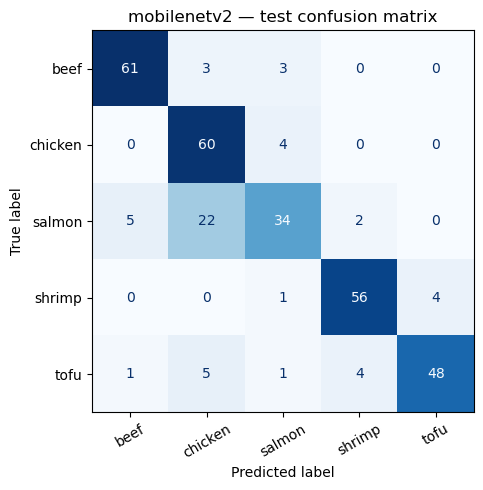

In [5]:
mobile_result = run_model("mobilenetv2")

### Model B — ResNet50 (medium)

Same dataset and same classifier, but a larger frozen feature extractor. This lets me see whether the extra parameters actually help.

Starting resnet50. Batch size=4
Training embeddings:
  Embedded 160/1135
  Embedded 320/1135
  Embedded 480/1135
  Embedded 640/1135
  Embedded 800/1135
  Embedded 960/1135
  Embedded 1120/1135
  Embedded 1135/1135
Validation embeddings:
  Embedded 160/189
  Embedded 189/189
Test embeddings:
  Embedded 160/314
  Embedded 314/314
Saved probe and results to /Users/timhamilton/models
resnet50: accuracy=0.857, macro-F1=0.853
              precision    recall  f1-score   support

        beef       0.86      0.96      0.91        67
     chicken       0.83      0.92      0.87        64
      salmon       0.84      0.65      0.73        63
      shrimp       0.91      0.87      0.89        61
        tofu       0.84      0.88      0.86        59

    accuracy                           0.86       314
   macro avg       0.86      0.86      0.85       314
weighted avg       0.86      0.86      0.85       314



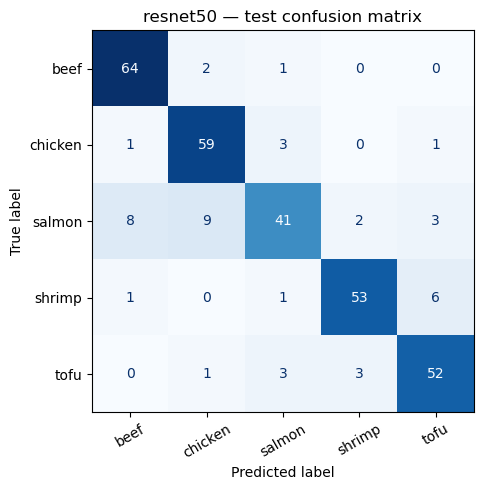

In [6]:
resnet_result = run_model("resnet50")

### Model C — EfficientNetV2M (large)

This is the most computationally demanding run. I’m keeping it separate so the smaller model results remain saved even if this one takes longer or needs a GPU.

Starting efficientnetv2m. Batch size=4
Training embeddings:
  Embedded 160/1135
  Embedded 320/1135
  Embedded 480/1135
  Embedded 640/1135
  Embedded 800/1135
  Embedded 960/1135
  Embedded 1120/1135
  Embedded 1135/1135
Validation embeddings:
  Embedded 160/189
  Embedded 189/189
Test embeddings:
  Embedded 160/314
  Embedded 314/314
Saved probe and results to /Users/timhamilton/models
efficientnetv2m: accuracy=0.854, macro-F1=0.853
              precision    recall  f1-score   support

        beef       0.87      0.91      0.89        67
     chicken       0.78      0.88      0.82        64
      salmon       0.84      0.73      0.78        63
      shrimp       0.96      0.84      0.89        61
        tofu       0.84      0.92      0.88        59

    accuracy                           0.85       314
   macro avg       0.86      0.85      0.85       314
weighted avg       0.86      0.85      0.85       314



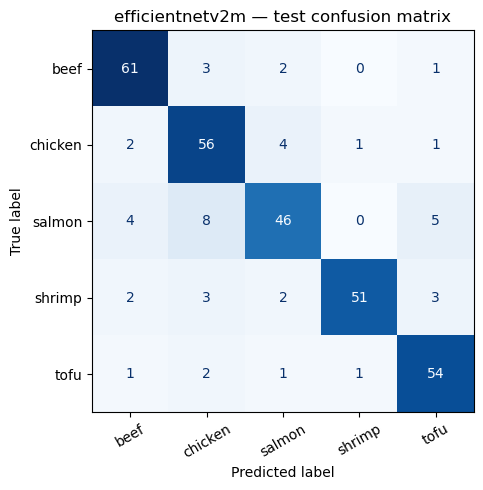

In [7]:
efficientnet_result = run_model("efficientnetv2m")

## 5. Compare model size, performance, and processing time

The table and plot below use the results saved by the individual model cells, so they can be regenerated without repeating feature extraction. I’m interested in whether accuracy actually improves as model size increases, and whether the improvement is worth the extra embedding time.

,application,backbone_parameters,embedding_dim,train_embedding_sec,test_embedding_sec,probe_parameters,probe_training_sec,epochs,test_accuracy,macro_f1
0,mobilenetv2,2257984,1280,116.660,33.505,6405,2.245,12,0.825,0.821
1,resnet50,23587712,2048,207.886,61.565,10245,1.886,10,0.857,0.853
2,efficientnetv2m,53150388,1280,466.605,124.399,6405,3.268,25,0.854,0.853


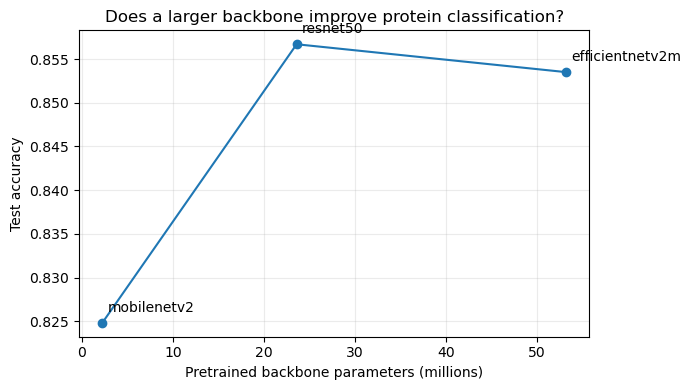

In [8]:
results = []
all_confusions = {}
for key in MODEL_SPECS:
    info_path = MODELS_DIR / f"P2_N3_{key}_results.json"
    pred_path = MODELS_DIR / f"P2_N3_{key}_predictions.npy"
    if not info_path.exists() or not pred_path.exists():
        raise FileNotFoundError(f"Finish the {key} model cell before comparing all three.")
    results.append(json.loads(info_path.read_text()))
    all_confusions[key] = confusion_matrix(
        y_test, np.load(pred_path), labels=range(N_CLASSES)
    )
comparison = pd.DataFrame(results).sort_values("backbone_parameters")
comparison.to_csv(MODELS_DIR / "P2_N3_comparison.csv", index=False)
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(comparison["backbone_parameters"] / 1e6, comparison["test_accuracy"], "o-")
for row in comparison.itertuples():
    ax.annotate(row.application,
                (row.backbone_parameters / 1e6, row.test_accuracy),
                xytext=(4, 8), textcoords="offset points")
ax.set_xlabel("Pretrained backbone parameters (millions)")
ax.set_ylabel("Test accuracy")
ax.set_title("Does a larger backbone improve protein classification?")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [9]:
best = comparison.loc[comparison["test_accuracy"].idxmax()]
small = comparison.iloc[0]
large = comparison.iloc[-1]
combined = sum(all_confusions.values())
off_diag = combined.copy()
np.fill_diagonal(off_diag, 0)
i, j = np.unravel_index(np.argmax(off_diag), off_diag.shape)
observed = (
    f"{class_names[i]} predicted as {class_names[j]} ({off_diag[i, j]} times)"
    if off_diag.sum() else "no misclassifications in the test set"
)
chicken_tofu = sum(
    cm[label_to_index["chicken"], label_to_index["tofu"]]
    + cm[label_to_index["tofu"], label_to_index["chicken"]]
    for cm in all_confusions.values()
)
display(Markdown(f"""
### What I found

- **Best test accuracy:** {best['application']} at **{best['test_accuracy']:.1%}**, with macro-F1 **{best['macro_f1']:.3f}**.
- **Small vs. large:** {small['test_accuracy']:.1%} versus {large['test_accuracy']:.1%}, a difference of **{(large['test_accuracy'] - small['test_accuracy']) * 100:+.1f} percentage points**.
- **Training embedding time:** {small['train_embedding_sec']:.1f} seconds for the small model versus {large['train_embedding_sec']:.1f} seconds for the large model.
- **Confusion check:** I predicted chicken and tofu would be confused most. Across the three models there were **{chicken_tofu}** chicken↔tofu mistakes. The most frequent directed error overall was **{observed}**.

**My takeaway:** The largest network is only worthwhile if its accuracy and recall gains justify the additional processing time. A good overall score doesn't automatically mean the model recognizes every protein equally well.
"""))


### What I found

- **Best test accuracy:** resnet50 at **85.7%**, with macro-F1 **0.853**.
- **Small vs. large:** 82.5% versus 85.4%, a difference of **+2.9 percentage points**.
- **Training embedding time:** 116.7 seconds for the small model versus 466.6 seconds for the large model.
- **Confusion check:** I predicted chicken and tofu would be confused most. Across the three models there were **10** chicken↔tofu mistakes. The most frequent directed error overall was **salmon predicted as chicken (39 times)**.

**My takeaway:** The largest network is only worthwhile if its accuracy and recall gains justify the additional processing time. A good overall score doesn't automatically mean the model recognizes every protein equally well.


## 6. Outputs for Notebooks 4 and 5

The `models/` folder contains `P2_N3_mobilenetv2.keras`, `P2_N3_resnet50.keras`, and `P2_N3_efficientnetv2m.keras` after all three runs finish, plus `label_mapping.json`. These `.keras` files store **only the trained linear probes**, not the pretrained ImageNet backbones.

Notebook 4 and the Streamlit app rebuild the backbones and attach the corresponding probe. I saved separate predictions and result summaries too, so I can revisit the comparison without rerunning the costly embeddings.

